Issues: 
1. AmpelHealpix.py computes the incorrect area
2. AmpelHealpix.py p_value pixel selection includes pixels that are far away from the best fit location -->
    It could be that something is wrong in my pixel to coord computation

In [1]:
# get an alert
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import json


# All imported in ic_visualization.py:
import requests #for url downloading
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.table import QTable
import astropy_healpix as ah
from regions import PointSkyRegion
import healpy as hp
import mhealpy as mhp
from mhealpy import HealpixMap
import ligo.skymap.plot
from ligo.skymap.io.fits import read_sky_map

sys.path.insert(1, '../../') #check where your ic_visualization.py file is, add path to it
from ic_visualization import plot_IC_alert, write_new_yaml, plot_zoomed_IC_alert, select_pixels, check_source_in_map
from params import p

import mhealpy as mh

from hop import Stream
from hop.io import StartPosition
#https://hop-client.readthedocs.io/en/latest/user/quickstart.html

stream = Stream(start_at=StartPosition.EARLIEST, until_eos=True)
alerts = []
with stream.open("kafka://kafka.scimma.org/gcn.notices.icecube.gold_bronze_track_alerts", "r") as s:
    for message in s:
         # print(message.content)
        alerts.append(message.content)
print('latest alert: ')
alerts[-1]


/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


latest alert: 


{'$schema': 'https://gcn.nasa.gov/schema/v6.1.1/gcn/notices/icecube/single_neutrino_alerts.schema.json',
 'mission': 'IceCube',
 'instrument': 'IC86',
 'messenger': 'Neutrino',
 'pipeline': 'Gold Track Alert',
 'record_number': 1,
 'event_name': ['IceCube-261012A'],
 'id': ['143283_53121260'],
 'alert_datetime': '2026-10-12T21:47:16.7Z',
 'alert_type': 'update',
 'alert_tense': 'current',
 'alert_topology': 'Track',
 'number_of_events': 1,
 'ra': 177.71,
 'dec': 8.95,
 'ra_dec_error': 0.45,
 'containment_probability': 0.9,
 'systematic_included': True,
 'healpix_url': 'https://roc-2.icecube.wisc.edu/public/alerts/IceCube-261012A_skymap_probdensity_multiorder.fits.gz',
 'trigger_time': '2026-10-12T16:58:11.468Z',
 'nu_energy': 242.25,
 'p_astro': 0.6095,
 'far': 2.4232e-08}

Map has masked values. reeplacing them with 0


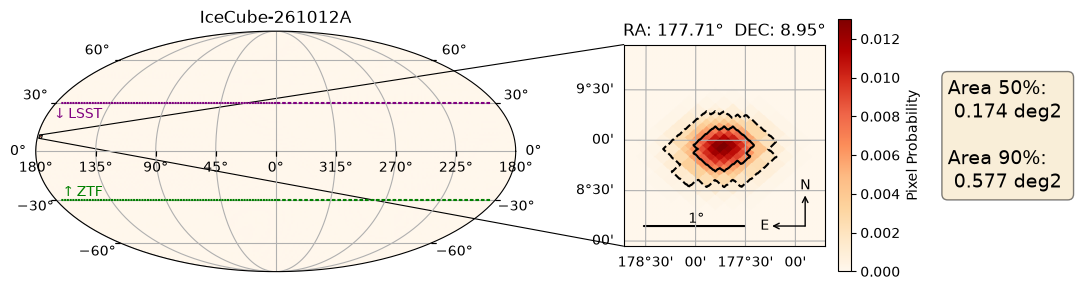

In [2]:
alert = alerts[-1]
map_path, A_90, m = plot_IC_alert(alert['healpix_url'], r=1, plot_prob_density=False)


In [3]:
def get_hpx_regions(alert_path, p_value):

        skymap = QTable.read(alert_path)
        prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)
        skymap.sort("PROBDENSITY", reverse=True)
        level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
        nside = ah.level_to_nside(level)

        cumprob = np.cumsum(prob_density)
        # searchsorted gives the FIRST index where cumprob >= target.
        i_region = cumprob.searchsorted(p_value)

        nside_selection = list(set(nside[:i_region]))
        masked_dict = {nside_i: [] for nside_i in nside_selection}
        for i in range(len(nside[:i_region])):
            masked_dict[nside[i]].append(ipix[i])

        masked_list = []
        for nside_i in masked_dict.keys():
            masked_list.append({
                 'nside': nside_i,
                 'pixels': masked_dict[nside_i]
            })
        return masked_list

        # print('NSIDE : ipix')
        # for i in range(len(nside[:i_region])):
        #      print(nside[i], ' : ', ipix[i])
        # masked_list = []
        # nsides = []
        # for nside_i in nside[:i_region]:
        #     if int(nside_i) not in nsides:
        #         nsides.append(int(nside_i))
        # for nside_i in nsides:
        #     masked_list.append({'nside': nside_i,
        #                     'pixels': []})
        # for nside_i, ipix_i in zip(nside[:i_region], ipix[:i_region]):
        #     for element in masked_list:
        #         if element['nside'] == int(nside_i):
        #             element['pixels'].append(int(ipix_i))
        
        # return masked_list

In [4]:
def get_hpx_regions(alert_path, p_value):
    # 1. Read the multi-order skymap FITS table
    skymap = QTable.read(alert_path)
    
    # 2. Sort the table by PROBDENSITY in descending order FIRST
    skymap.sort("PROBDENSITY", reverse=True)
    
    # 3. Extract level and ipix from the sorted UNIQ column
    level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
    nside = ah.level_to_nside(level)

    print(skymap['PROBDENSITY'])
    # 4. Convert probability density and calculate individual pixel probabilities
    prob_density = skymap['PROBDENSITY']#.to_value(u.deg**-2)
    pixel_area = ah.nside_to_pixel_area(nside)

    print(pixel_area)
    prob = pixel_area * prob_density
    
    # 5. Compute cumulative probability and find threshold index
    cumprob = np.cumsum(prob)
    i_region = cumprob.searchsorted(p_value)
    
    # 6. Group selected pixels up to i_region + 1 (inclusive of the boundary pixel)
    selected_nside = nside[:i_region + 1]
    selected_ipix = ipix[:i_region + 1]
    
    nside_selection = list(set(selected_nside))
    masked_dict = {nside_i: [] for nside_i in nside_selection}
    
    for i in range(len(selected_nside)):
        masked_dict[selected_nside[i]].append(selected_ipix[i])

    masked_list = []
    for nside_i in masked_dict.keys():
        masked_list.append({
            'nside': int(nside_i),
            'pixels': masked_dict[nside_i]
        })
        
    return masked_list

In [13]:
hpx_regions = get_hpx_regions(map_path, 0.9)
hpx_regions

[——— ——— ——— ...  0.  0.  0.] 1 / sr
[0.00409062 0.00409062 0.00409062 ... 0.00409062 0.00409062 0.00409062] sr


[{'nside': 16, 'pixels': [np.int64(2857)]}]

[——— ——— ——— ...  0.  0.  0.] 1 / sr
[0.00409062 0.00409062 0.00409062 ... 0.00409062 0.00409062 0.00409062] sr
Map has masked values. reeplacing them with 0


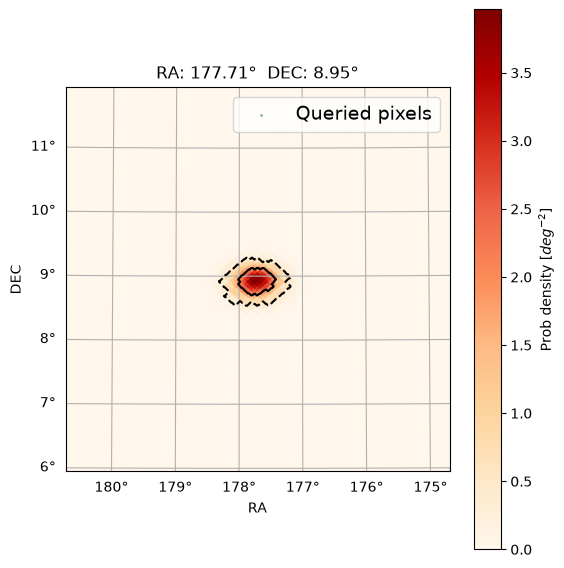

('/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/ic_alerts/IceCube-261012A_skymap_probdensity_multiorder.fits.gz',
 [<Quantity 286.875>],
 [<Quantity -66.44353569>])

In [ ]:

plot_zoomed_IC_alert(alert['healpix_url'],
                      debug=get_hpx_regions(map_path, 0.9))

In [7]:
sel_pixels_lat = []
sel_pixels_lon = []
for dict_nside in hpx_regions:
    nside = dict_nside['nside']
    pixels = dict_nside['pixels']
    lon, lat = ah.healpix_to_lonlat(pixels, nside=nside, order='nested')
    sel_pixels_lat.extend(lat.to('deg') / u.deg)
    sel_pixels_lon.extend(lon.to('deg') / u.deg)

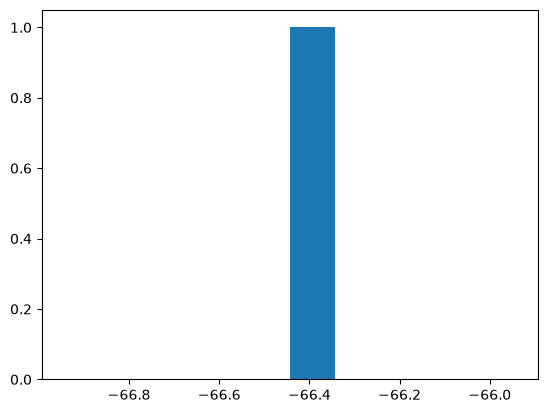

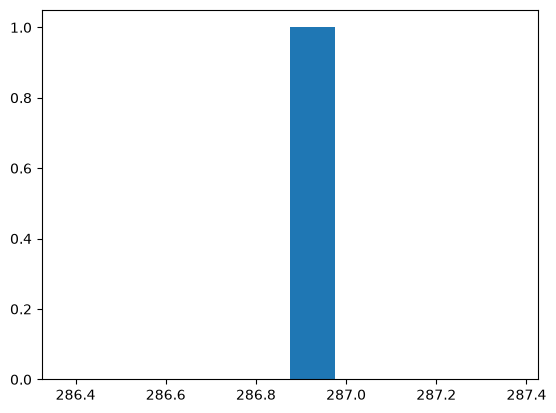

In [8]:
plt.hist(sel_pixels_lat)
plt.show()
plt.hist(sel_pixels_lon)
plt.show()